### 1. Prepare the data
1. Create a new notebook in which you load the titanic dataset (see `data` folder).
2. Keep the following columns, filter out the rest: `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked, Survived`.
3. Drop all NAs values using: `df = df.dropna()`
4. One-hot encode the attributes `Sex` and `Embarked` using the following code:
    `df = pd.get_dummies(df, columns=["Sex", "Embarked"], dtype=float)`
5. Take `survived` as label and the other columns as features.
6. Do a train-test-split with 20% test data and set `random_state=0`
7. Standardize the features. Fit the scaler on the training data only, then apply it to both sets.

In [88]:
import pandas as pd
import torch
import numpy as np
import plotly.express as px

In [89]:
df = pd.read_csv(r"ml2-ws26/data/titanic.csv")

In [90]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [91]:
keep = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]
df_new = df[keep]
df_new

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0
...,...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,S,0
887,1,female,19.0,0,0,30.0000,S,1
888,3,female,NaN,1,2,23.4500,S,0
889,1,male,26.0,0,0,30.0000,C,1


In [92]:
df_new = df_new.dropna()
df_new = df_new.reset_index(drop=True)

In [93]:
df_new = pd.get_dummies(df_new, columns=["Sex", "Embarked"], dtype=float)

In [94]:
y = df_new["Survived"]
x = df_new.drop("Survived", axis=1)

In [95]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

print("Train data points:", len(X_train))
print("Test data points:", len(X_test))

Train data points: 569
Test data points: 143


In [96]:
df_new

,Pclass,Age,SibSp,Parch,Fare,Survived,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0,0.0,1.0,0.0,0.0,1.0
1,1,38.0,1,0,71.2833,1,1.0,0.0,1.0,0.0,0.0
2,3,26.0,0,0,7.9250,1,1.0,0.0,0.0,0.0,1.0
3,1,35.0,1,0,53.1000,1,1.0,0.0,0.0,0.0,1.0
4,3,35.0,0,0,8.0500,0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
707,3,39.0,0,5,29.1250,0,1.0,0.0,0.0,1.0,0.0
708,2,27.0,0,0,13.0000,0,0.0,1.0,0.0,0.0,1.0
709,1,19.0,0,0,30.0000,1,1.0,0.0,0.0,0.0,1.0
710,1,26.0,0,0,30.0000,1,0.0,1.0,1.0,0.0,0.0


In [97]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)

In [98]:
X_test_scaled = scaler.transform(X_test)

### 2. Train a neural network
1. Train a neural network with one hidden layer of size 5 and ReLu as activation for this layer (no activation on the output layer).
2. Use `CrossEntropyLoss` and a `SGD` optimizer with learning rate 0.001
3. Train the network for 200 epochs and print the loss every 20 epochs.
4. Plot the loss plot as shown above.
5. Predict on the test data with the trained network and measure accuracy.

In [99]:
import torch
torch.manual_seed(0) # to ensure reproducibility

In [100]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [101]:
df_new.dtypes

Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Survived        int64
Sex_female    float64
Sex_male      float64
Embarked_C    float64
Embarked_Q    float64
Embarked_S    float64
dtype: object

In [102]:
train_y = torch.tensor(y_train.values).to(device)
test_y = torch.tensor(y_test.values).to(device)

In [104]:
train_x = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
test_x = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
train_y = torch.tensor(y_train.values, dtype=torch.long).to(device)
test_y = torch.tensor(y_test.values, dtype=torch.long).to(device)

print(train_x.shape, train_y.shape, train_y.dtype)

torch.Size([569, 10]) torch.Size([569]) torch.int64


In [105]:
import torch.nn as nn

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(10, 5)  # 10 Features rein, 5 Neuronen
        self.output = nn.Linear(5, 2)   # 2 Klassen (gestorben / überlebt)

    def forward(self, x):
        a = torch.relu(self.hidden(x))  # ReLU nur auf der Hidden Layer
        return self.output(a)           # keine Aktivierung am Output (Logits)

In [106]:
dnn = NeuralNetwork()
print("Number of parameters:", sum(p.numel() for p in dnn.parameters()))
dnn.to(device)            # copy the model to the device
dnn.train()      # set model into training mode

Number of parameters: 67


NeuralNetwork(
  (hidden): Linear(in_features=10, out_features=5, bias=True)
  (output): Linear(in_features=5, out_features=2, bias=True)
)

In [111]:
no_epochs = 200
learning_rate = 0.001

loss_func = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(dnn.parameters(), lr=learning_rate)

losses = []
for iteration in range(no_epochs):

    optimizer.zero_grad()
    y_hat = dnn(train_x) # we predict on all data points (= batch gradient descent)

    loss = loss_func(y_hat, train_y) # calculate the loss
    loss.backward() # backpropagate the loss to calculate gradients
    optimizer.step() # update the weights using these gradients

    losses.append(loss.item())
    if iteration % 20 == 0:
        print(f"Loss in epoch {iteration} is {loss.item()}")

Loss in epoch 0 is 0.7859742045402527
Loss in epoch 20 is 0.7804707288742065
Loss in epoch 40 is 0.7751942276954651
Loss in epoch 60 is 0.7701393365859985
Loss in epoch 80 is 0.7652857303619385
Loss in epoch 100 is 0.7606209516525269
Loss in epoch 120 is 0.7561312317848206
Loss in epoch 140 is 0.7518157958984375
Loss in epoch 160 is 0.7476714849472046
Loss in epoch 180 is 0.7436695694923401


Text(0, 0.5, 'loss')

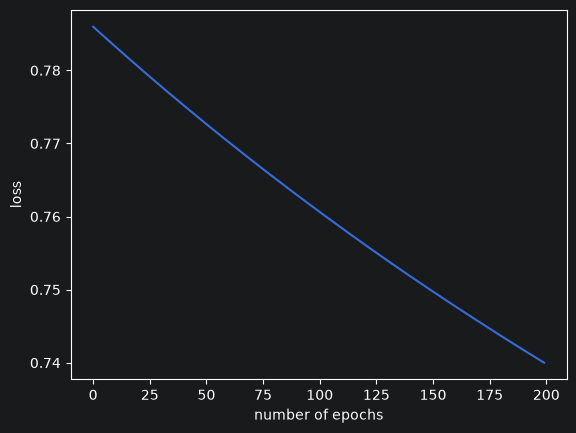

In [112]:
import matplotlib.pyplot as plt
fig = plt.figure()
plt.plot(range(0, no_epochs), losses)
plt.xlabel('number of epochs')
plt.ylabel('loss')

In [109]:
dnn.eval()
y_pred = dnn(test_x)
predicted = torch.argmax(y_pred.data, 1)
correct = (predicted == test_y).sum().item()
accuracy = correct / len(test_x)

print(f"Accuracy is {100. * accuracy}%")

Accuracy is 38.46153846153847%
